In [1]:
from itertools import product
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import fastplotlib as fpl

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Unable to find extension: VK_EXT_swapchain_colorspace


Available devices:
🯄 | AMD Radeon Graphics (RADV REMBRANDT) | IntegratedGPU | Vulkan | Mesa 22.3.6
✅ (default) | NVIDIA T1200 Laptop GPU | DiscreteGPU | Vulkan | 535.129.03
❗ | llvmpipe (LLVM 15.0.6, 256 bits) | CPU | Vulkan | Mesa 22.3.6 (LLVM 15.0.6)
❗ | AMD Radeon Graphics (rembrandt, LLVM 15.0.6, DRM 3.52, 6.4.0-0.deb12.2-amd64) | Unknown | OpenGL | 


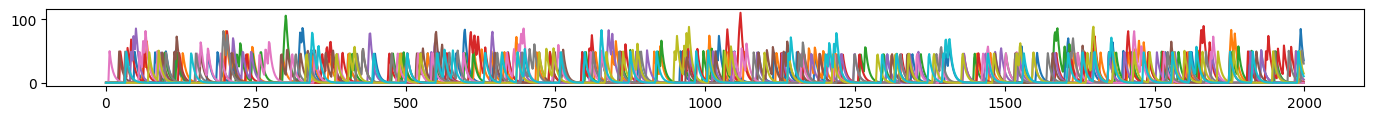

In [730]:
n_timepoints = 1_000
n_components = 10
interp_factor = 2

clean = np.zeros((n_components, n_timepoints * interp_factor))

x = 0
a = 0.7

b = 0

firing_prop = 0.05

spikes = list()

for i in range(n_components):
    spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(float))

for c_ix in range(n_components):
    for i in range(2, n_timepoints):
        clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2]) + (50 * spikes[c_ix][i])

    x_ = np.arange(0, n_timepoints * interp_factor)
    xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
    clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

n_timepoints *= 2

fig = plt.figure(figsize=(17, 1))
for i in range(n_components):
    plt.plot(clean[i])

In [785]:
noise = 15

In [786]:
n_pixels = 3

series = list()

for i in range(n_components):
    for j in range(n_pixels):
        noisy = clean[i] + np.random.normal(scale=noise, size=n_timepoints)
        noisy -= noisy.mean()
        series.append(noisy)

series = np.vstack(series)

<Axes: >

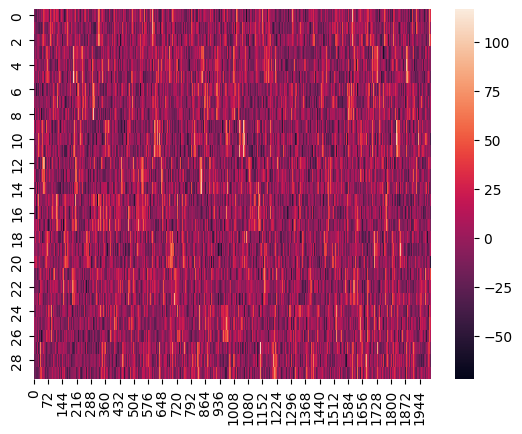

In [787]:
sns.heatmap(series)

In [788]:
series[-1] = np.random.normal(scale=noise, size=n_timepoints)
series[-1] -= series[-1].mean()

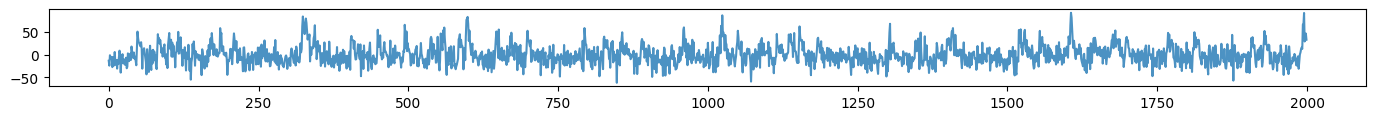

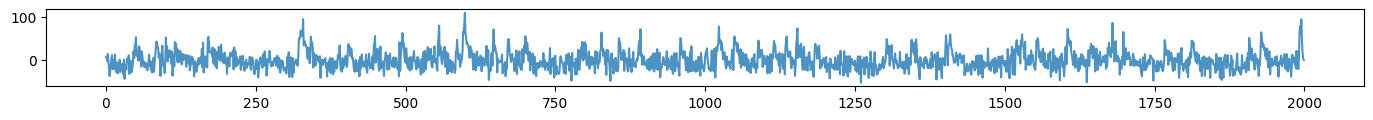

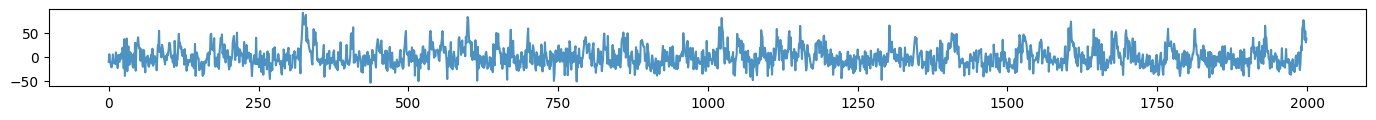

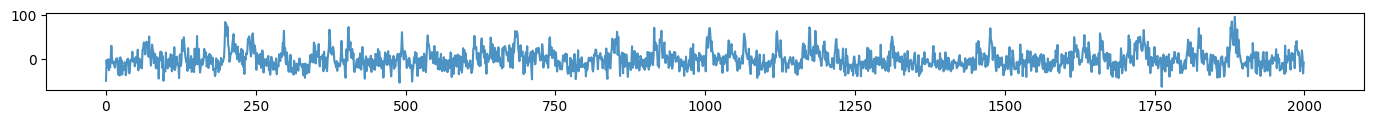

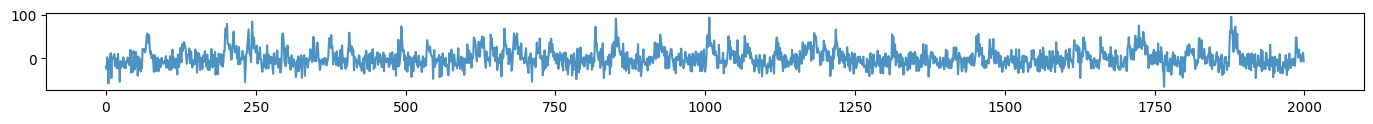

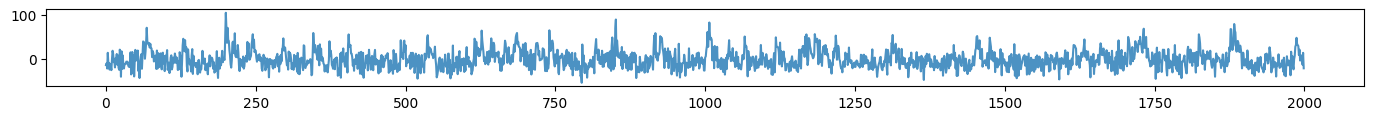

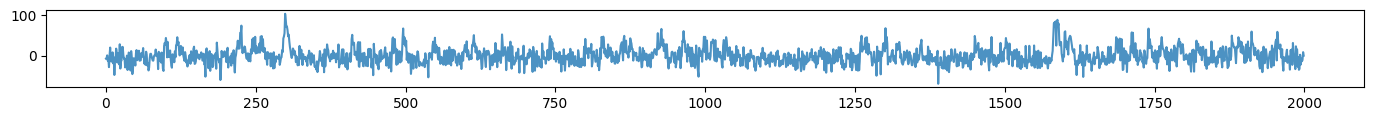

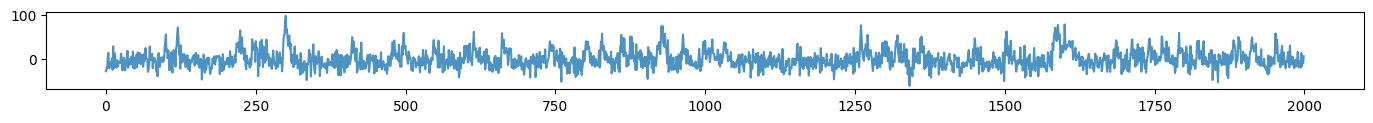

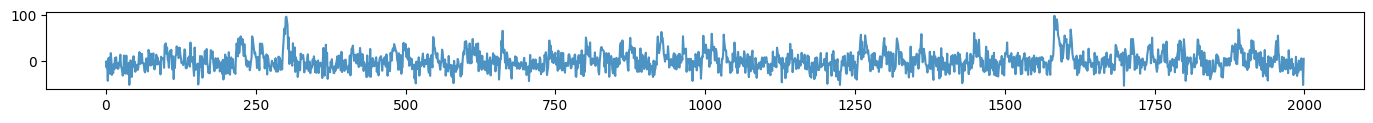

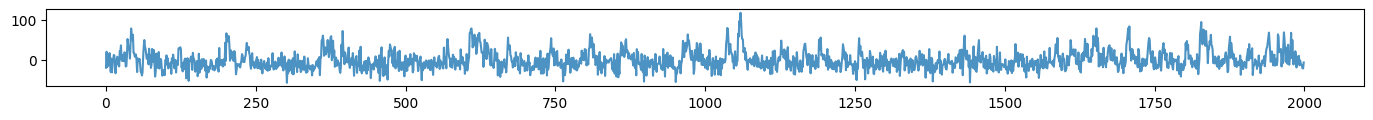

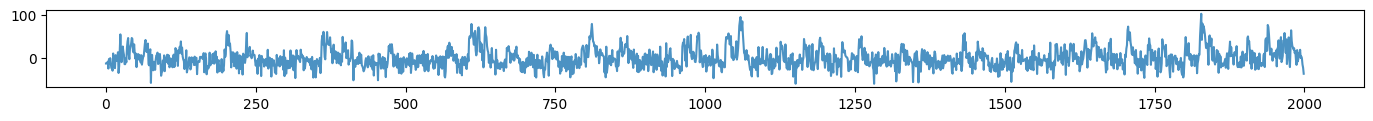

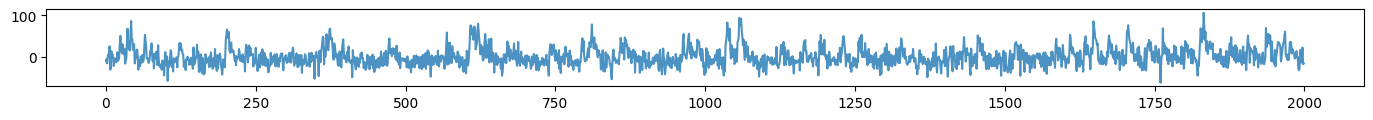

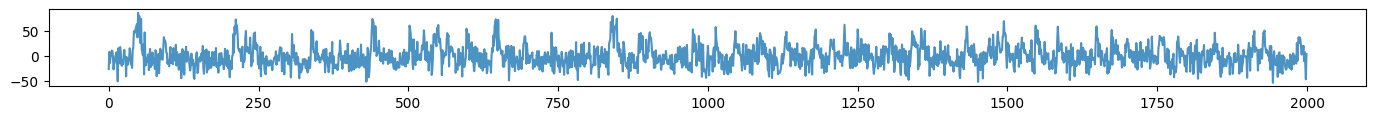

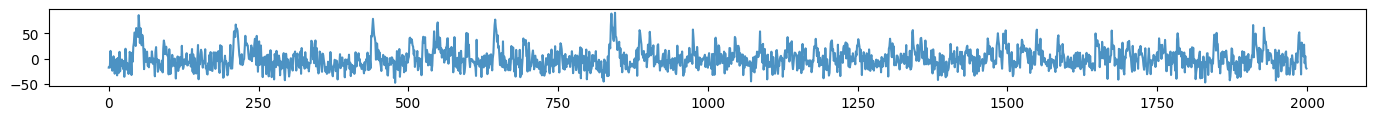

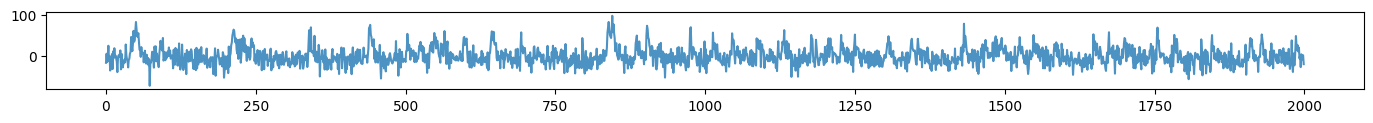

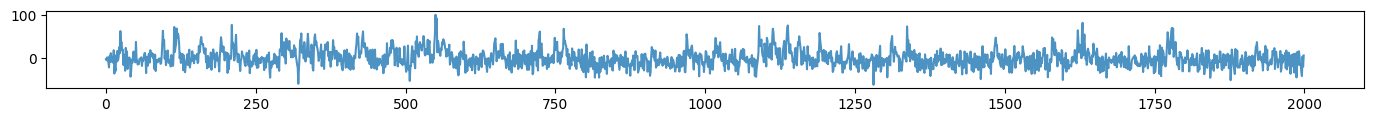

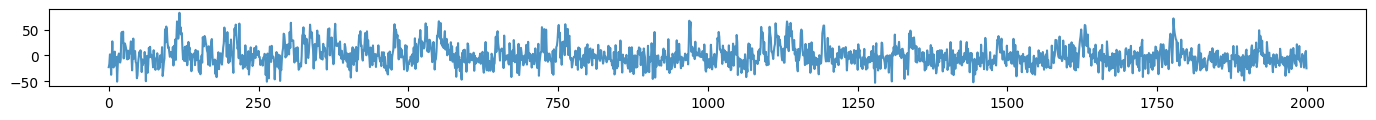

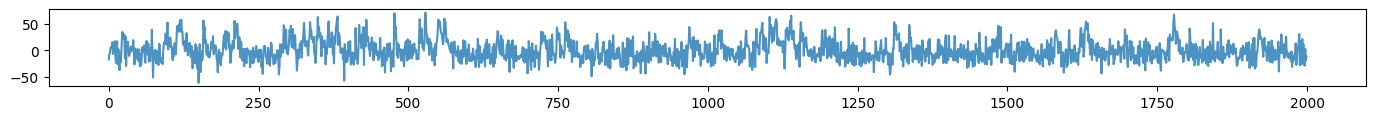

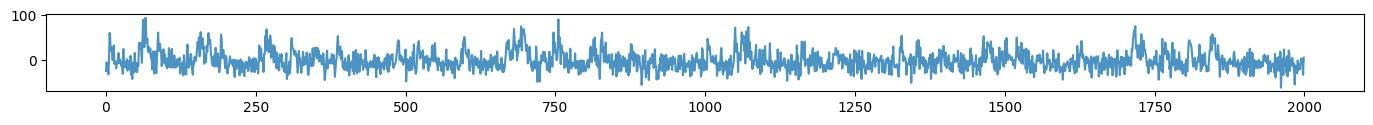

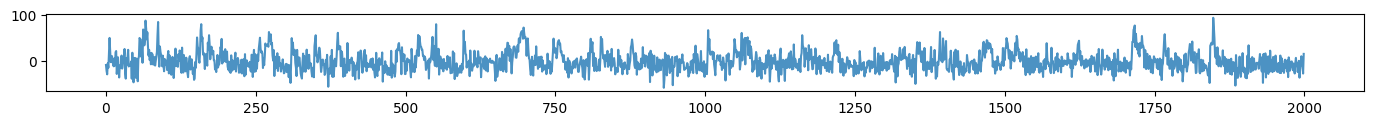

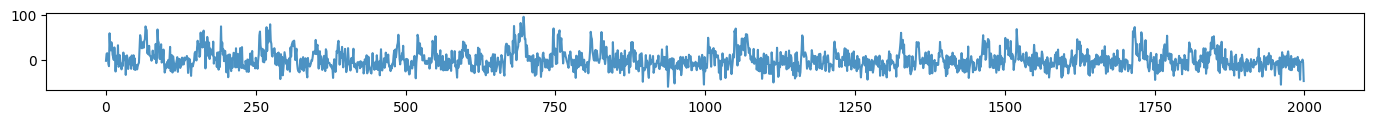

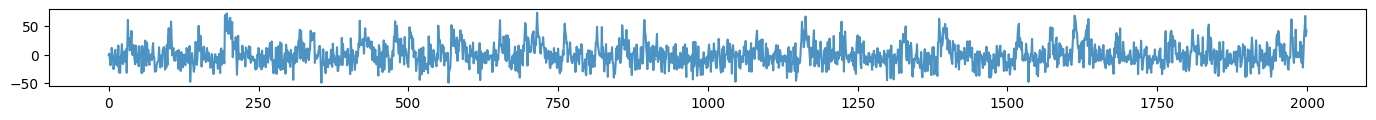

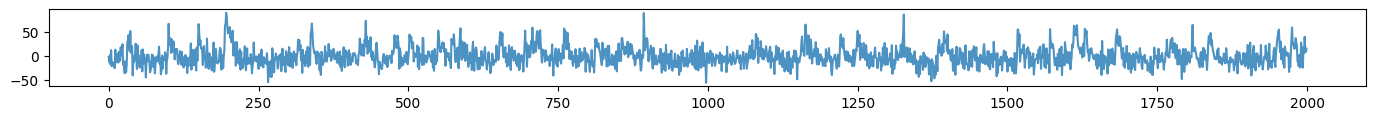

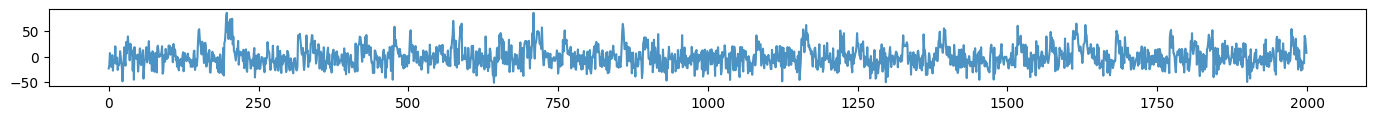

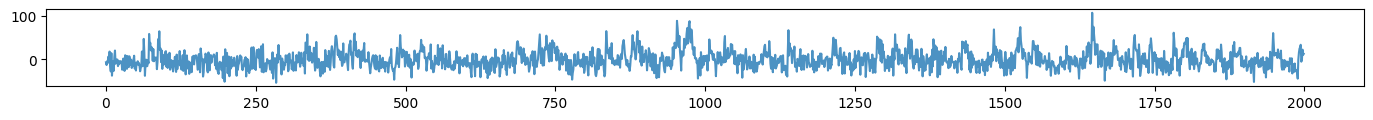

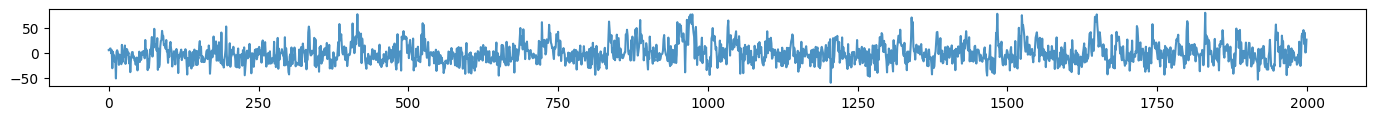

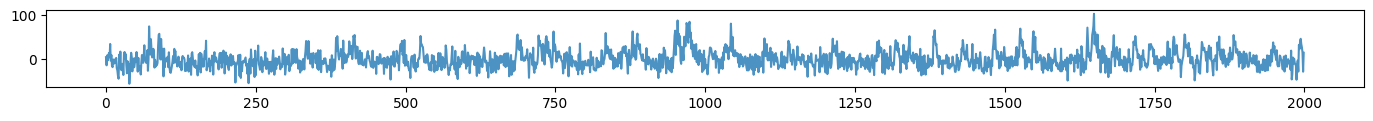

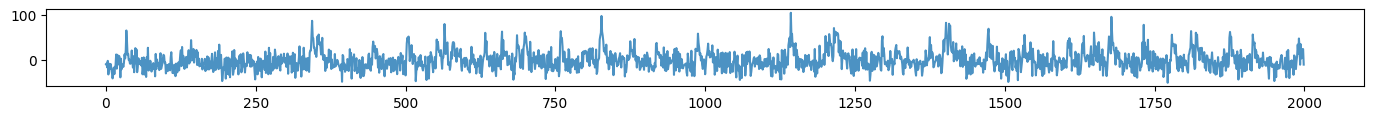

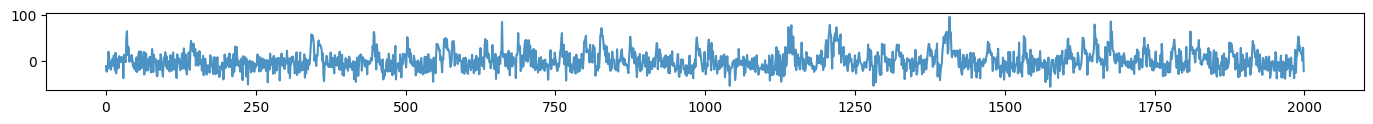

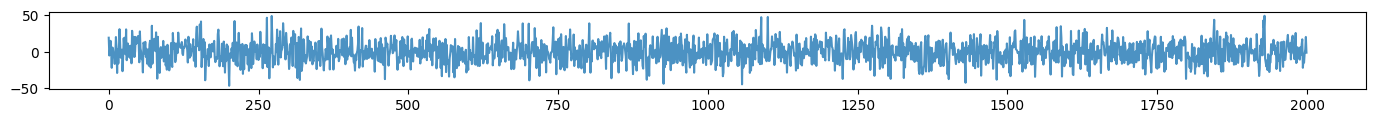

In [789]:
for i in range(n_pixels * n_components):
    fig = plt.figure(figsize=(17, 1))
    plt.plot(series[i], alpha=0.8)
    plt.show()

# plt.plot(clean, c="k", alpha=0.3)

In [790]:
def plot_regular_svd(Y):
    u, s, v = linalg.svd(Y)

    fig = plt.figure(figsize=(5, 2))
    plt.plot(s)
    plt.title("S")
    plt.show()
    fig, axs = plt.subplots(1, 2, figsize=(15, 5))
    sns.heatmap(u, ax=axs[0])
    axs[0].set_title("U")
    sns.heatmap(v[:10], ax=axs[1])
    axs[1].set_title("V")
    plt.show()
    
    for i in range(n_components):
        fig = plt.figure(figsize=(20, 2))
        plt.plot(clean[i, :500], c="k")
        plt.twinx()
        plt.plot(v[i, :500])
    sns.heatmap(u[:, :10])
    plt.title("first 10 U")

    return v[0]

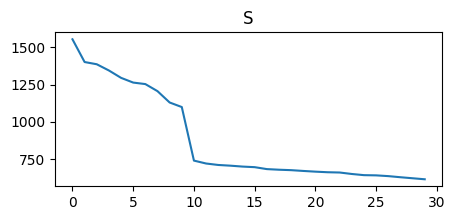

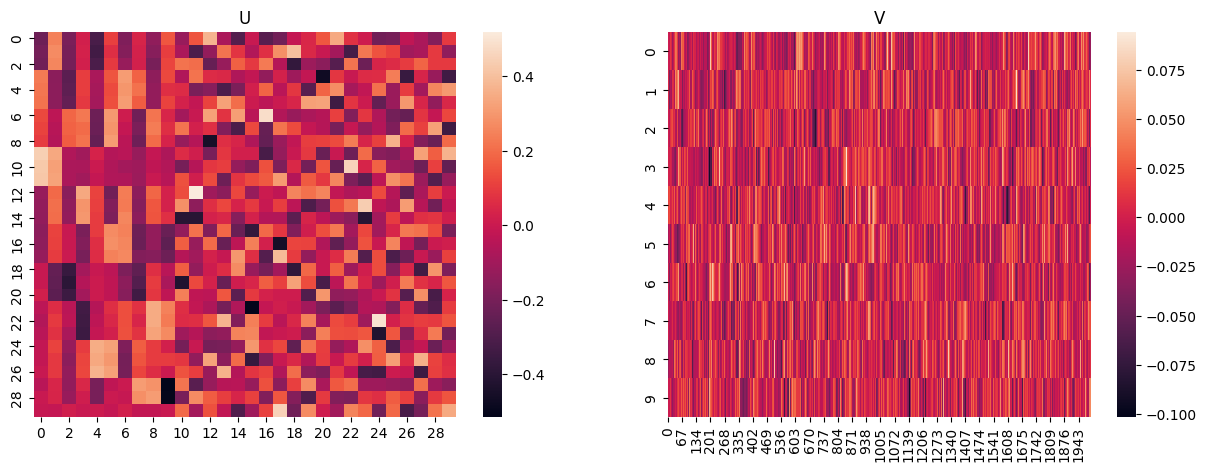

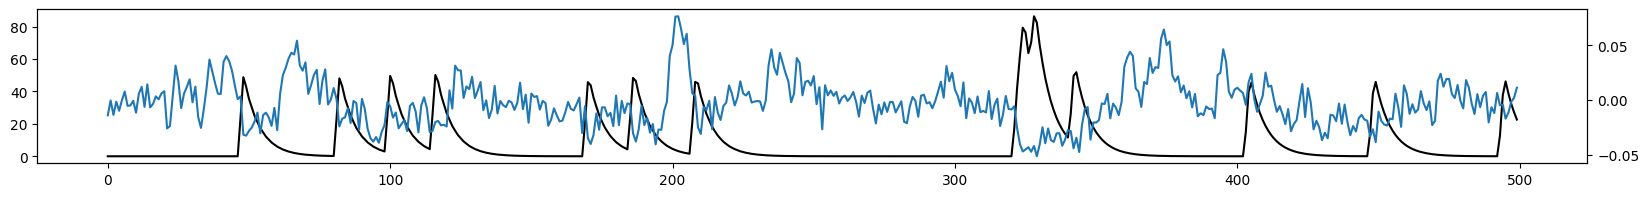

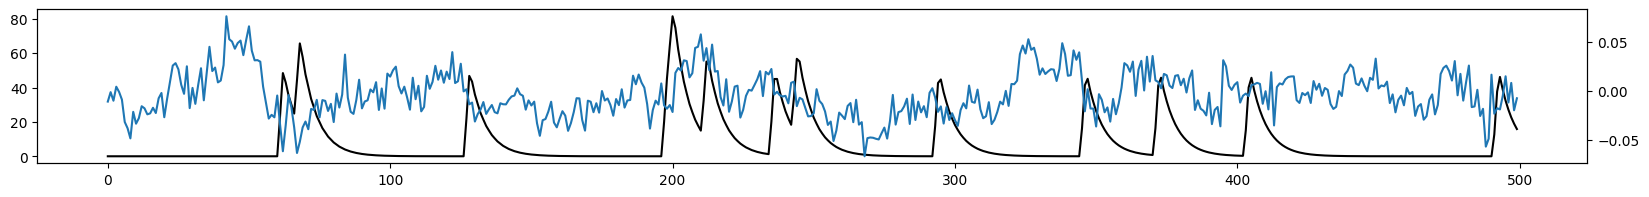

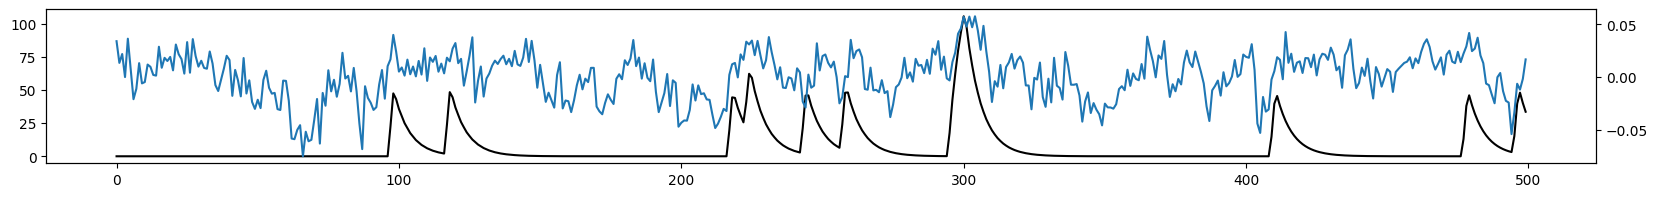

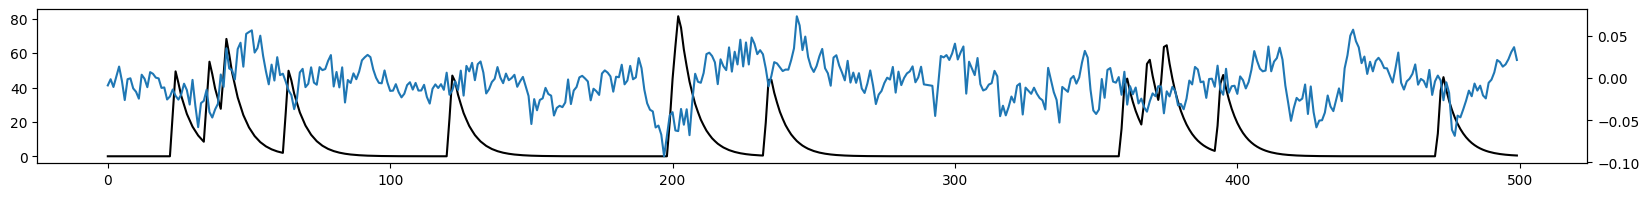

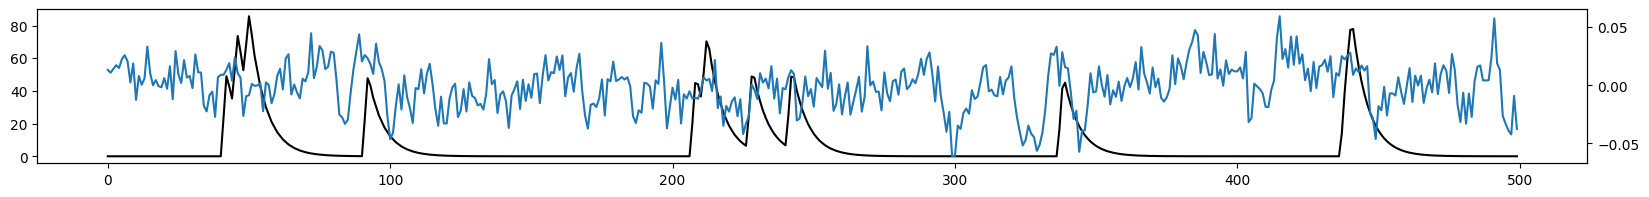

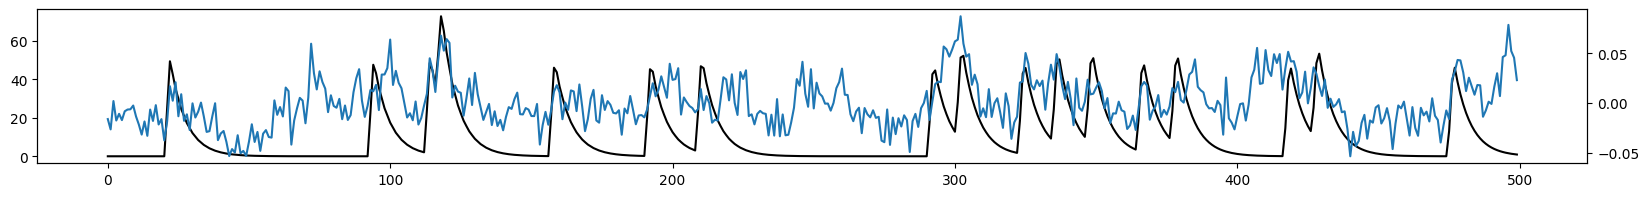

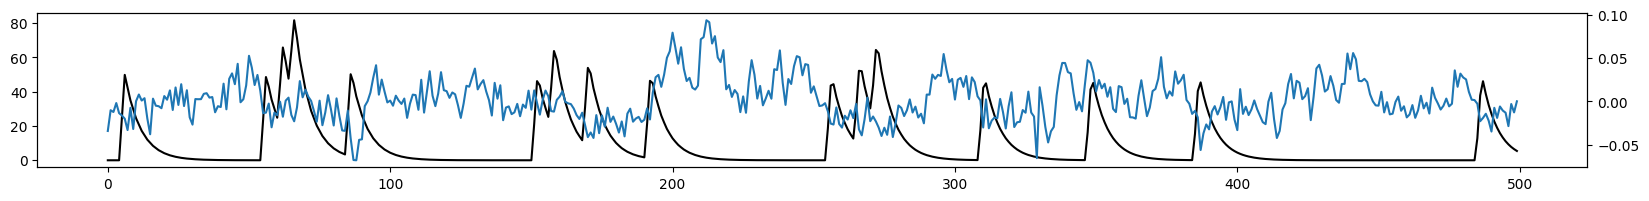

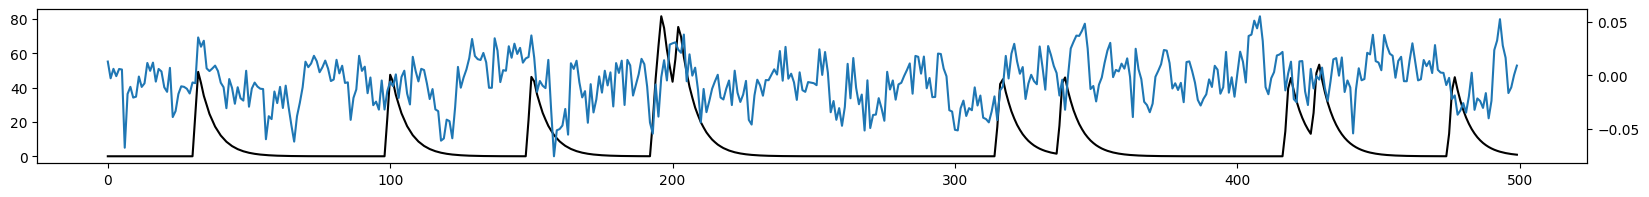

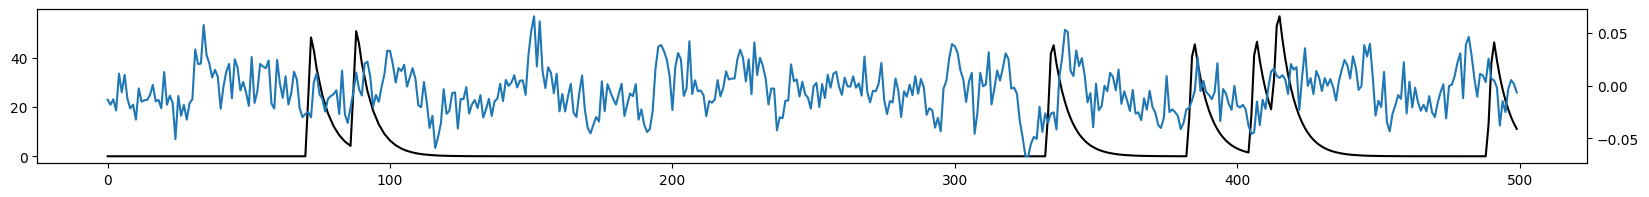

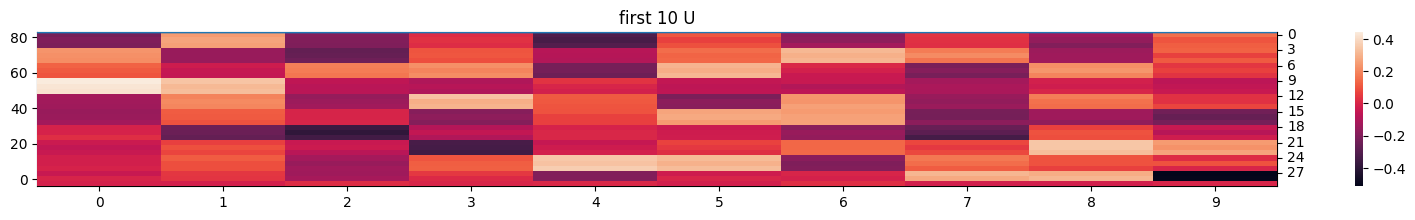

In [791]:
v0 = plot_regular_svd(series)

In [792]:
series.mean(axis=1)

array([ 6.25277607e-16, -3.69482223e-16,  1.13686838e-16,  7.95807864e-16,
       -6.25277607e-16, -4.83169060e-16, -4.83169060e-16,  2.84217094e-16,
       -1.05160325e-15,  7.95807864e-16,  7.95807864e-16,  6.82121026e-16,
        3.97903932e-16, -4.83169060e-16,  1.13686838e-15, -1.02318154e-15,
       -2.27373675e-16,  1.13686838e-15,  1.13686838e-16, -6.82121026e-16,
       -9.09494702e-16,  1.70530257e-16, -2.84217094e-16, -9.66338121e-16,
        1.19371180e-15, -2.38742359e-15,  1.70530257e-16,  4.54747351e-16,
        3.41060513e-16,  1.77635684e-16])

In [793]:
series.std(axis=1)

array([21.3193167 , 21.38080401, 21.21289205, 21.19958646, 20.98563999,
       20.76580988, 20.85023553, 20.22927297, 20.58477114, 22.78721857,
       22.3774506 , 22.32053274, 21.52222981, 20.56978572, 21.0800754 ,
       20.50388172, 20.57780859, 19.84655144, 20.64723287, 21.38720925,
       21.18377637, 19.89039201, 19.93709936, 20.0107422 , 20.6193423 ,
       20.58400024, 20.61612361, 21.27046721, 20.97157446, 14.86860024])

In [794]:
series.ptp(axis=1)

array([153.22853909, 162.95662814, 146.8561374 , 158.8482489 ,
       160.47145835, 158.80344826, 174.03167508, 158.76481911,
       153.28296408, 172.60322095, 161.87045687, 169.85860894,
       139.05305137, 139.16610436, 168.87218029, 162.65052305,
       135.38207603, 131.93523538, 155.02179396, 150.80575306,
       156.5078231 , 123.68176365, 145.74538285, 136.99198686,
       161.07015205, 139.32000255, 159.93865519, 154.20925869,
       152.66066587,  95.8481667 ])

In [795]:
from scipy import linalg

In [796]:
import seaborn as sns

/tmp/ipykernel_627775/1268377926.py:28: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


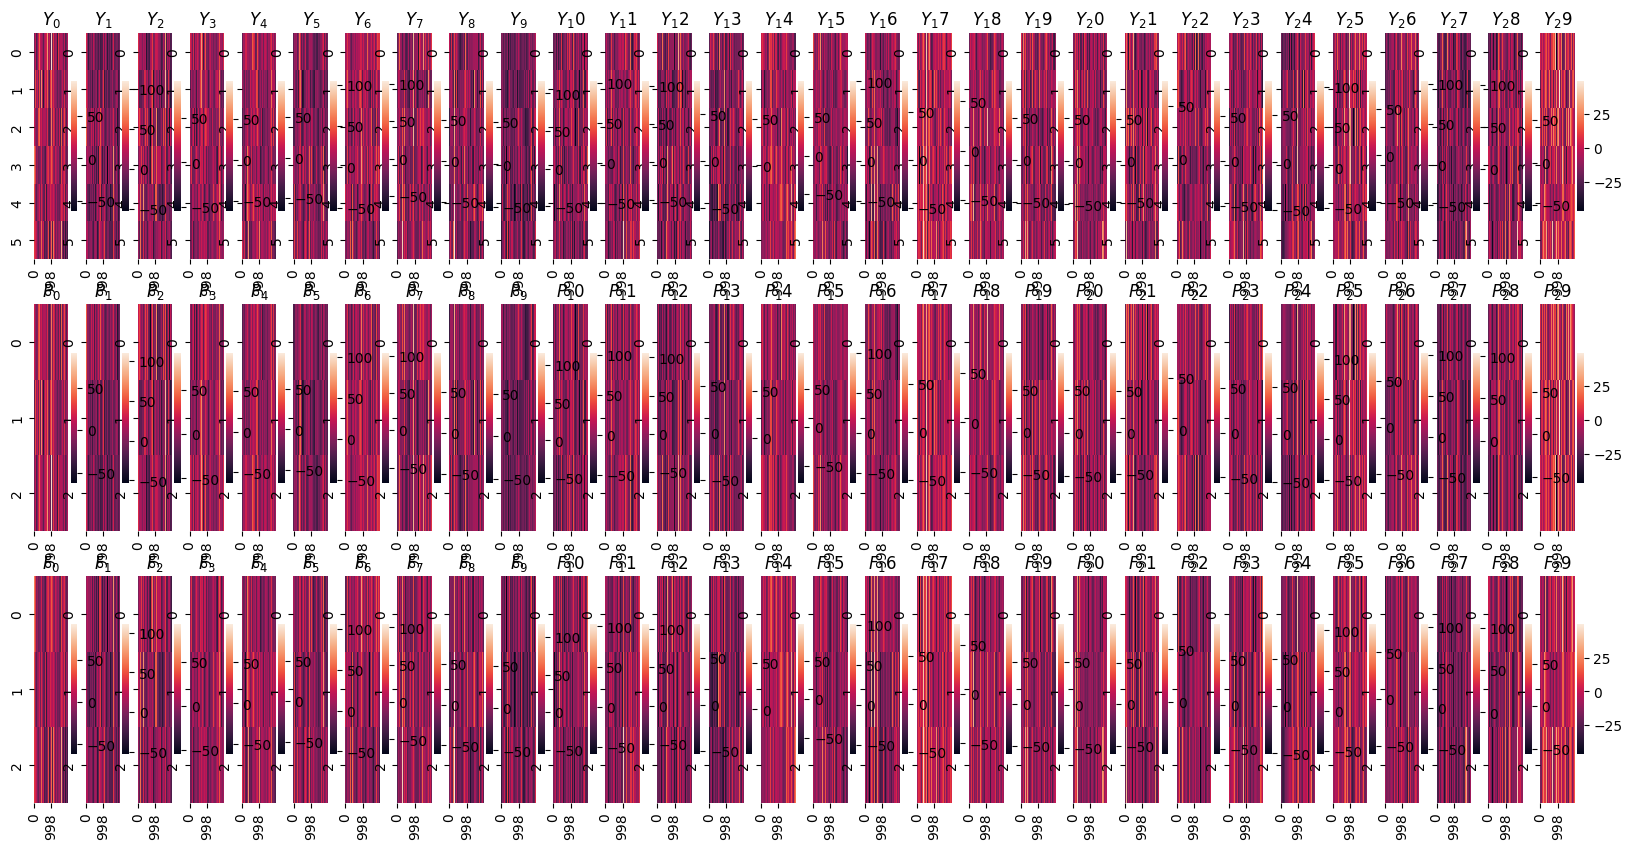

In [797]:
center = 100
w = 6

Ys = list()
Ps = list()
Fs = list()

fig, axs = plt.subplots(3, series.shape[0], figsize=(20, 10))

for i in range(series.shape[0]):
    y = linalg.hankel(series[i, :w], series[i, w:])
    p = np.flipud(y[:int(w / 2)])
    f = y[int(w / 2):]

    Ys.append(y)
    Ps.append(p)
    Fs.append(f)
        
    sns.heatmap(y, ax=axs[0, i])
    axs[0, i].set_title(f"$Y_{i}$")

    sns.heatmap(p, ax=axs[1, i])
    axs[1, i].set_title(f"$P_{i}$")

    sns.heatmap(f, ax=axs[2, i])
    axs[2, i].set_title(f"$F_{i}$")

plt.tight_layout()

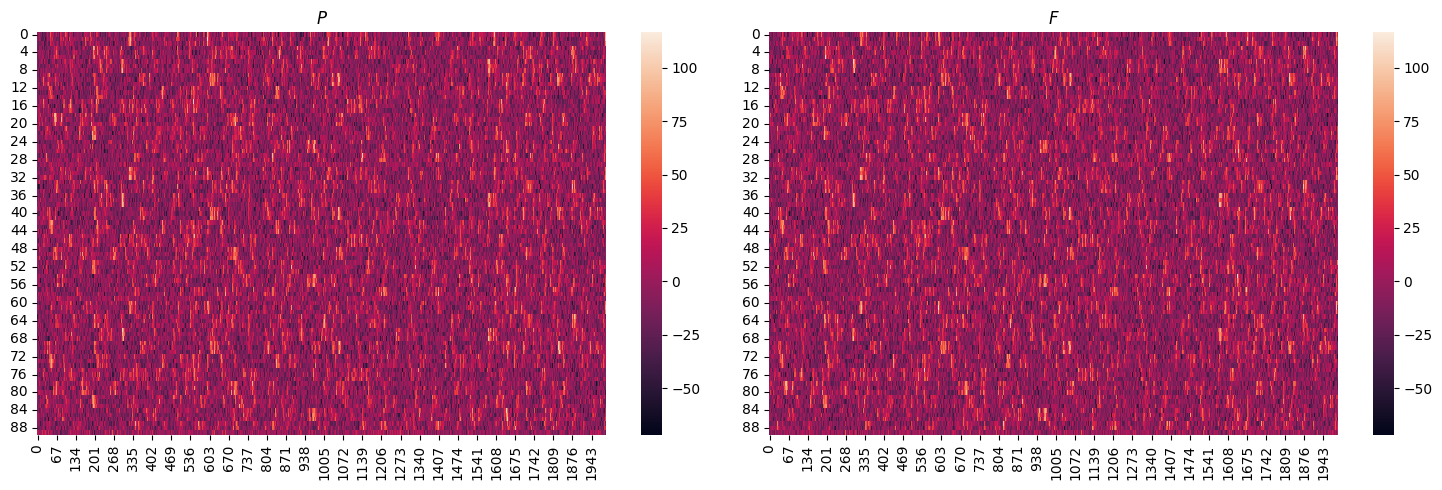

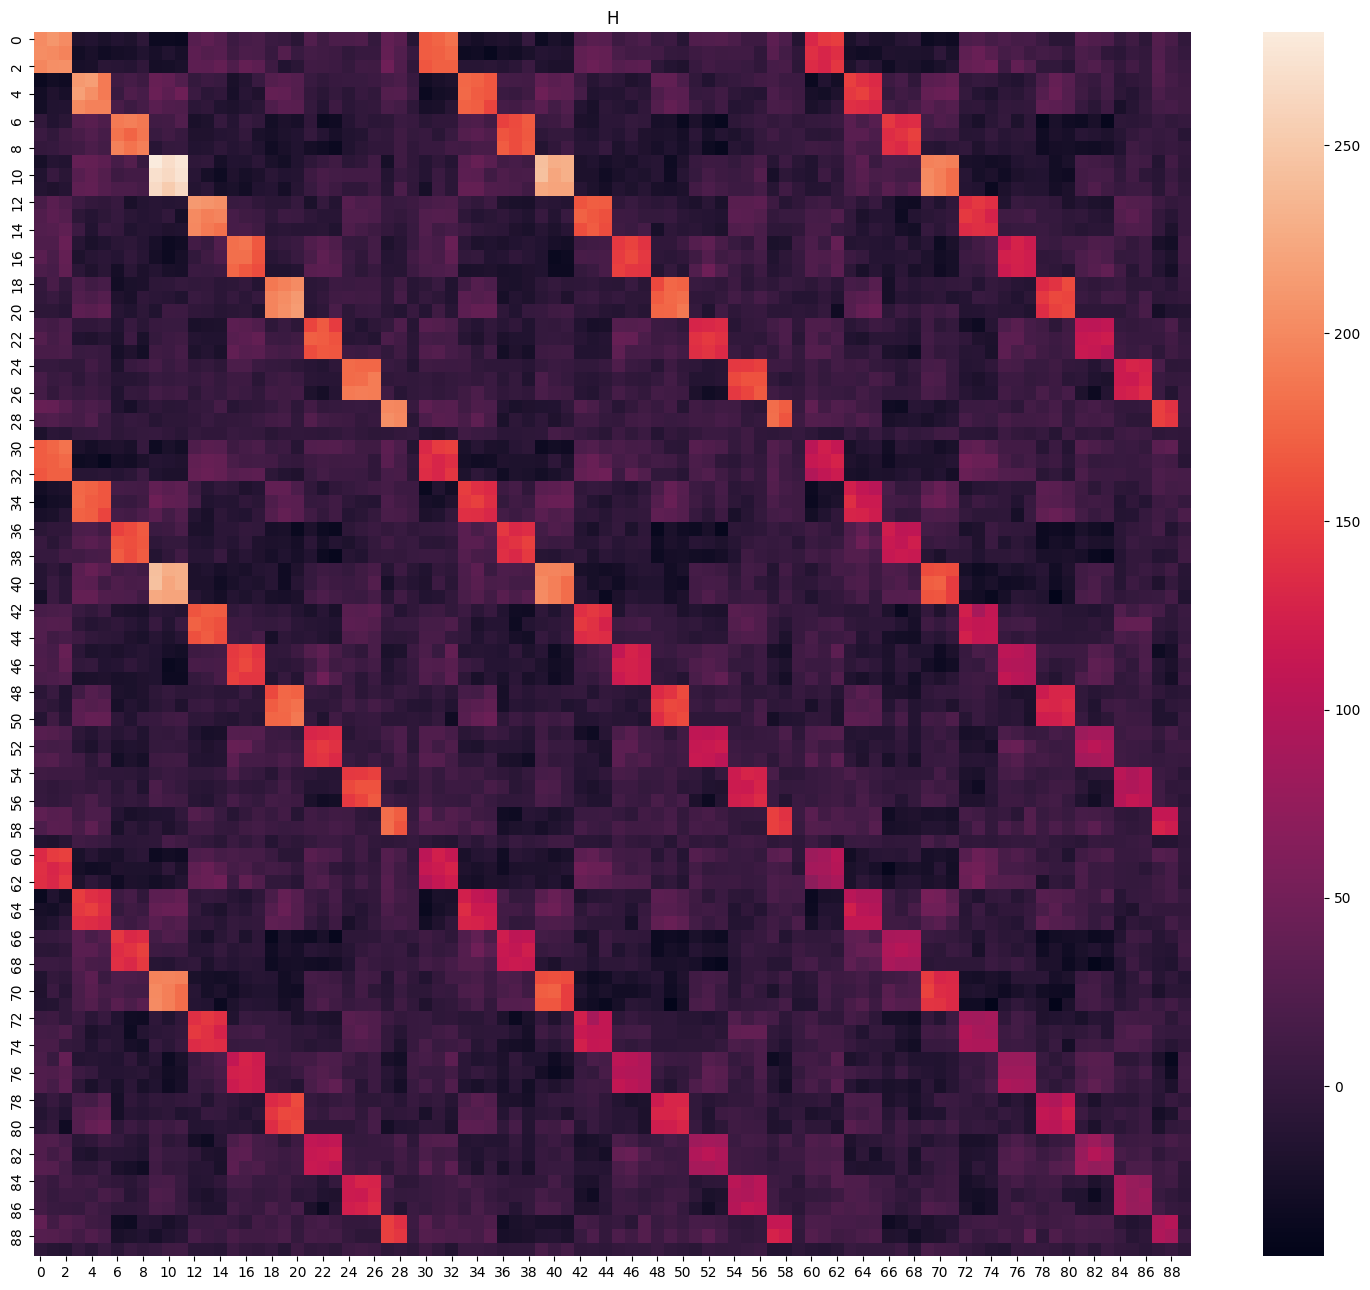

In [798]:
P_F_shape = (int(w / 2) * series.shape[0], n_timepoints - w)

P = np.zeros(P_F_shape)
F = np.zeros(P_F_shape)

for i in range(series.shape[0]):
    P[i::series.shape[0]] = Ps[i]
    F[i::series.shape[0]] = Fs[i]

fig, axs = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(P, ax=axs[0])
axs[0].set_title(f"$P$")

sns.heatmap(F, ax=axs[1])
axs[1].set_title(f"$F$")
fig.tight_layout()
plt.show()

H = (F @ P.T) / P.shape[1]

fig = plt.figure(figsize=(15, 13))
sns.heatmap(H, annot=False, fmt="0.1f")
plt.title("H")
fig.tight_layout()
plt.show()

In [799]:
from itertools import product

In [800]:
iterator = [tuple(reversed(ixs)) for ixs in product(*[range(0, int(w / 2) * series.shape[0], series.shape[0])]*2)]
iterator

[(0, 0),
 (30, 0),
 (60, 0),
 (0, 30),
 (30, 30),
 (60, 30),
 (0, 60),
 (30, 60),
 (60, 60)]

In [801]:
Hp = np.zeros((int(w / 2)**2, series.shape[0]**2))

for row_ix, (block_row_ix, block_col_ix) in enumerate(iterator):
    Hp[row_ix] = H[block_row_ix:block_row_ix + series.shape[0], block_col_ix:block_col_ix + series.shape[0]].ravel()

<Axes: >

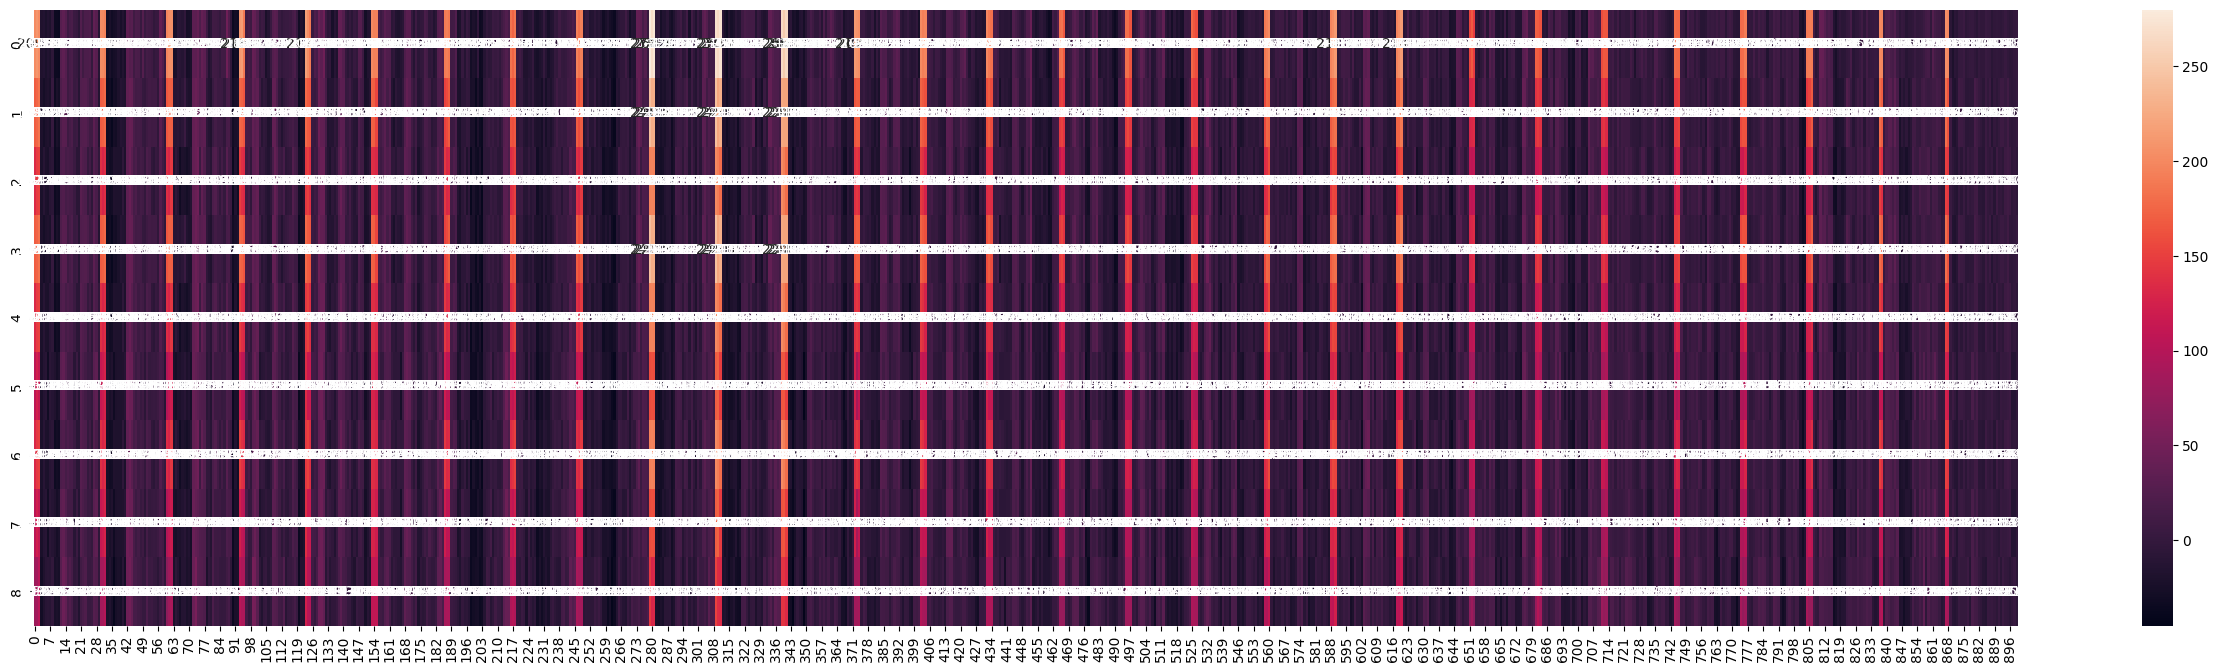

In [802]:
fig = plt.figure(figsize=(32, 8))

sns.heatmap(Hp, annot=True, fmt="0.1f")

In [803]:
u, s, v = linalg.svd(Hp)

Text(0.5, 1.0, 'V')

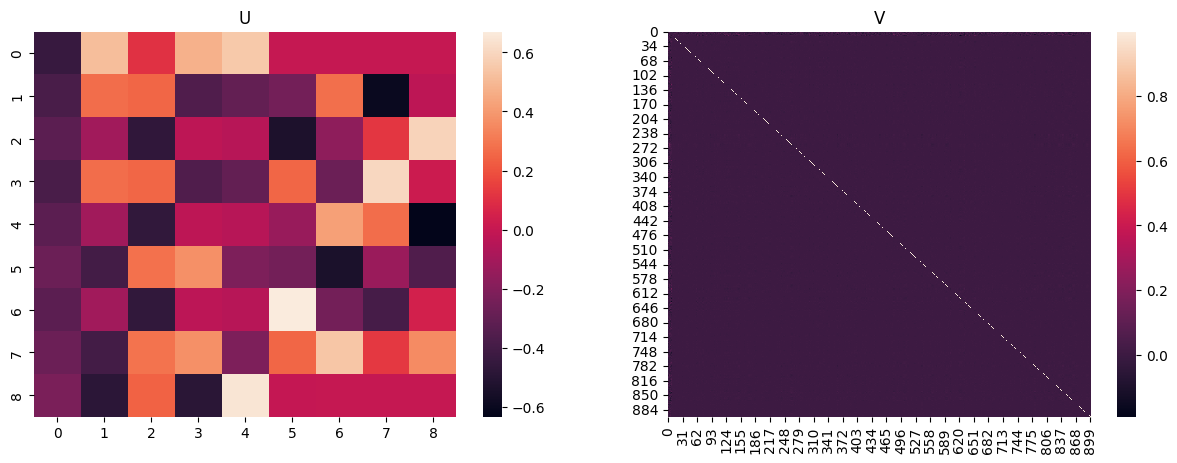

In [804]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(u, ax=axs[0])
axs[0].set_title("U")
sns.heatmap(v, ax=axs[1])
axs[1].set_title("V")

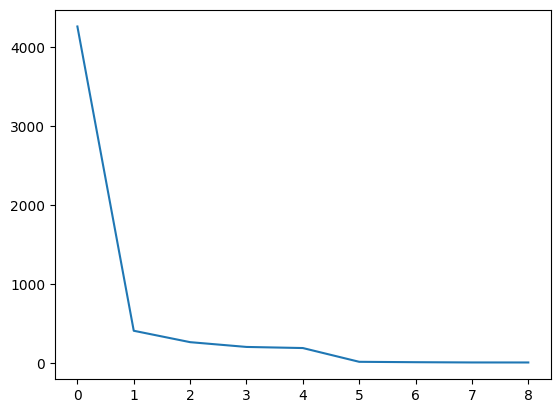

In [805]:
plt.plot(s)

Text(0.5, 1.0, '$V^r$')

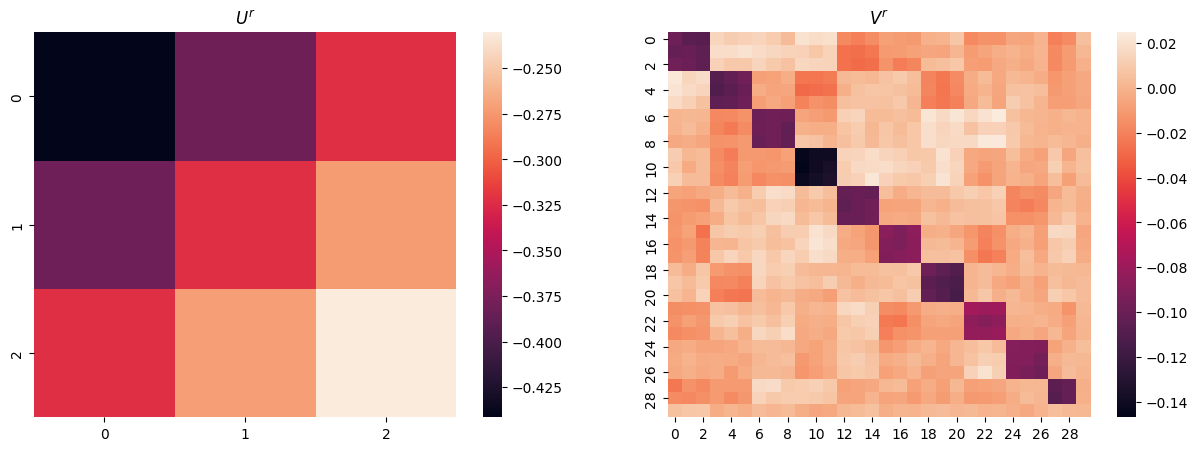

In [806]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
u_r = u[:, 0].reshape(int(w / 2), int(w / 2))
sns.heatmap(u_r, ax=axs[0])
axs[0].set_title("$U^r$")

v_r = v[0].reshape(series.shape[0], series.shape[0])
sns.heatmap(v_r, ax=axs[1])
axs[1].set_title("$V^r$")

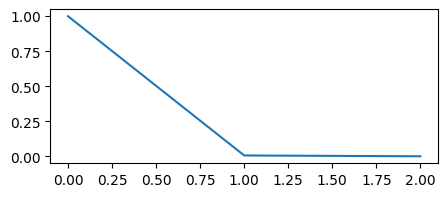

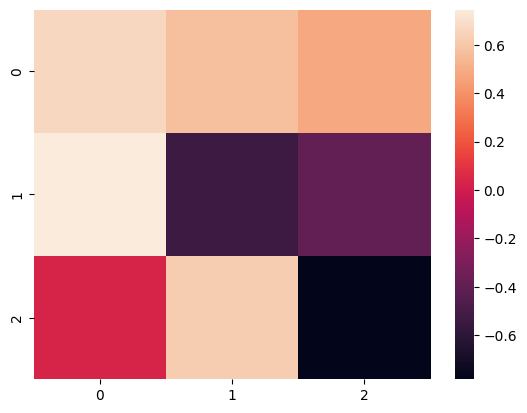

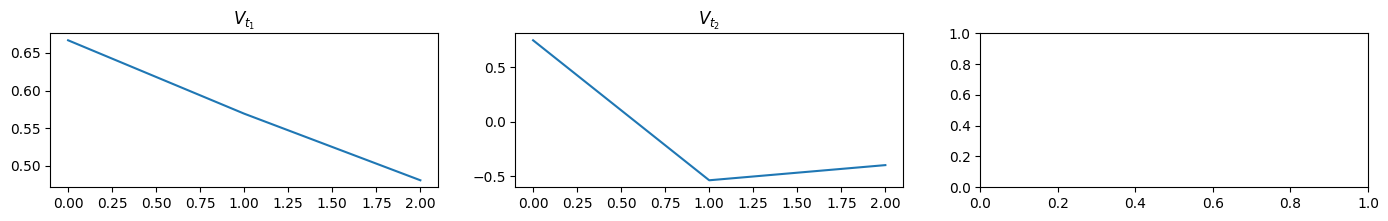

In [807]:
u_t, s_t, v_t = linalg.svd(u_r)

fig = plt.figure(figsize=(5, 2))
plt.plot(s_t)
plt.show()

sns.heatmap(v_t)
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(17, 2))

for i in range(2):
    axs[i].plot(v_t[i])
    axs[i].set_title(f"$V_{{t_{i + 1}}}$")
    
plt.show()

In [808]:
from sklearn.decomposition import SparsePCA

In [809]:
u_s, s_s, v_s = linalg.svd(v_r)

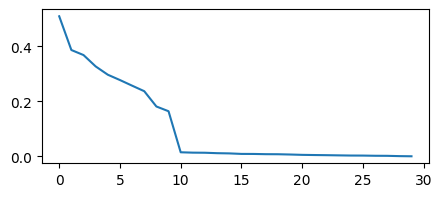

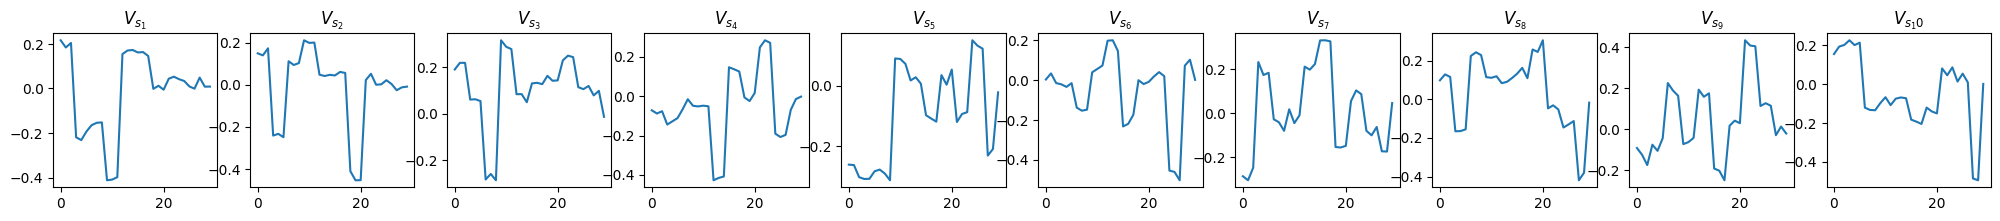

In [810]:
fig = plt.figure(figsize=(5, 2))
plt.plot(s_s)

fig, axs = plt.subplots(1, n_components, figsize=(25, 2))

for i in range(n_components):
    axs[i].plot(v_s[i])
    axs[i].set_title(f"$V_{{s_{i + 1}}}$")

plt.show()

In [811]:
pca = SparsePCA(n_components=n_components, alpha=0.03, U_init=u_s, V_init=v_s)

u_s = pca.fit_transform(v_r)
v_s = pca.components_

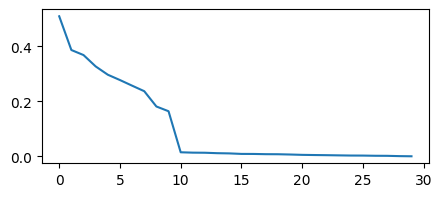

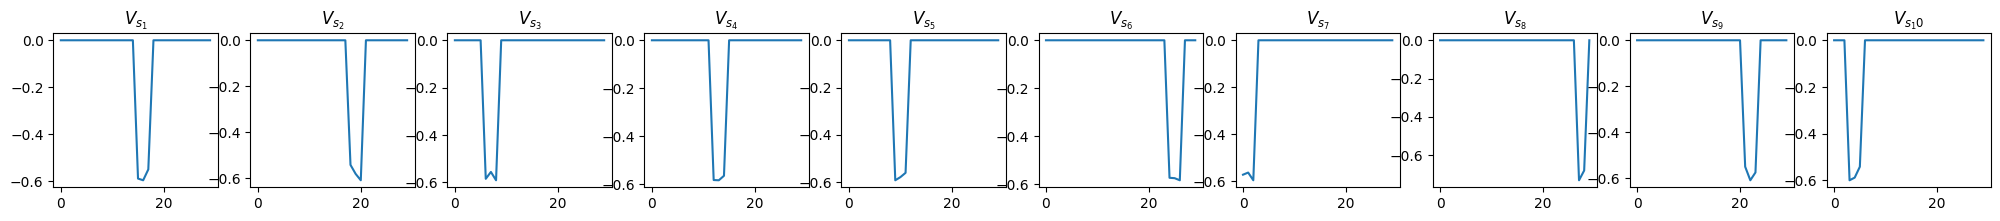

In [812]:
fig = plt.figure(figsize=(5, 2))
plt.plot(s_s)

fig, axs = plt.subplots(1, n_components, figsize=(25, 2))

for i in range(n_components):
    axs[i].plot(v_s[i])
    axs[i].set_title(f"$V_{{s_{i + 1}}}$")

plt.show()

<Axes: >

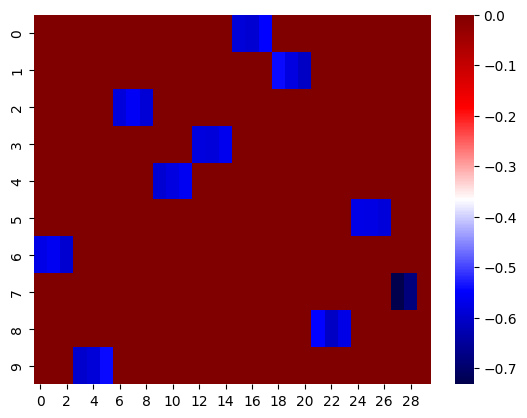

In [813]:
sns.heatmap(v_s[:n_components], cmap="seismic")

In [831]:
component_ixs = list()
for i in range(0, v_s.shape[1], int(w / 2)):
    component_ixs.append(np.abs(v_s[:, i]).argmax())

In [833]:
component_ixs

[6, 9, 2, 4, 3, 0, 1, 8, 5, 7]

In [834]:
v_s[0]

array([-0.        , -0.        , -0.        , -0.        , -0.        ,
       -0.        , -0.        , -0.        , -0.        , -0.        ,
       -0.        , -0.        , -0.        , -0.        , -0.        ,
       -0.58757718, -0.59482907, -0.54857218, -0.        , -0.        ,
       -0.        , -0.        , -0.        , -0.        , -0.        ,
       -0.        , -0.        , -0.        , -0.        , -0.        ])

In [835]:
filts = list()

for i in range(n_components):
    filts.append(np.kron(v_t[0], v_s[i]))

# Should be easier to interpret if I stack instead of interlace

In [836]:
filts = np.vstack(filts)

<Axes: >

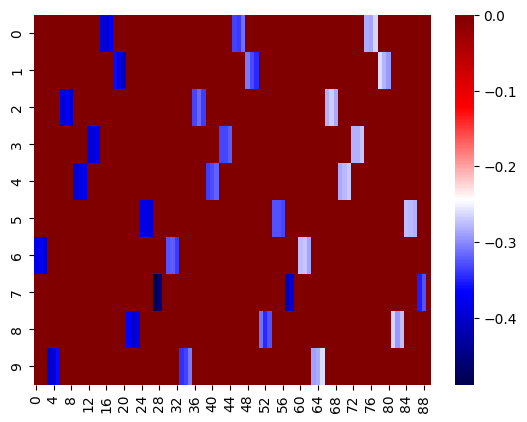

In [837]:
sns.heatmap(filts, cmap="seismic")

In [838]:
P.shape

(90, 1994)

In [839]:
v0 = -v0

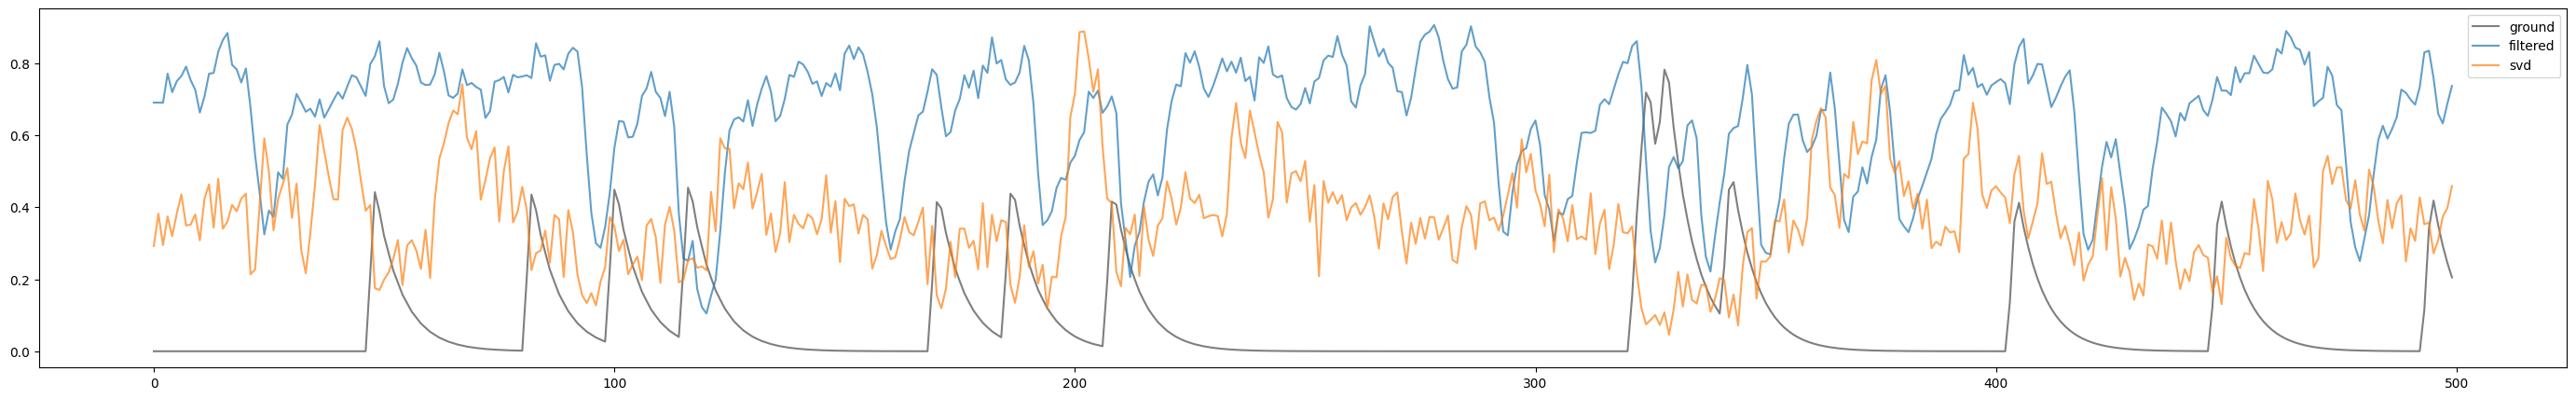

In [840]:
filtered = np.zeros(shape=(n_timepoints - int(w / 2)))
filtered[int(w / 2):] = filts[0] @ P
filtered = filtered

filtered -= filtered.min()
filtered /= filtered.max()

indices = slice(0, 500)
fig = plt.figure(figsize=(35, 5))
plt.plot(clean[0, indices] / clean.max(), label="ground", alpha=0.5, c="k")
plt.plot(filtered[indices], label="filtered", alpha=0.7)
v0 -= v0.min()
v0 /= v0.max()
plt.plot(v0[indices], label="svd", alpha=0.7)
# plt.plot(series[:3].mean(axis=0)[indices] / clean.max(), alpha=0.7, label="simple mean")
plt.legend()
plt.show()

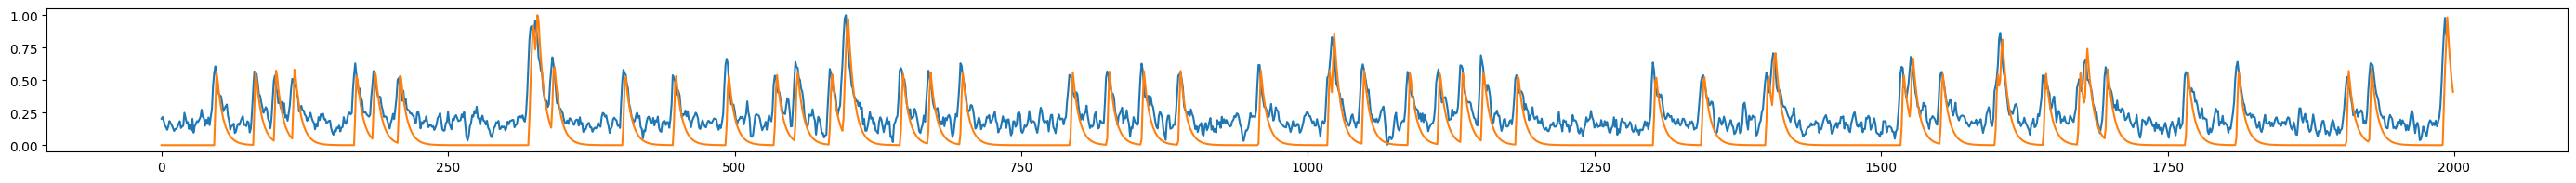

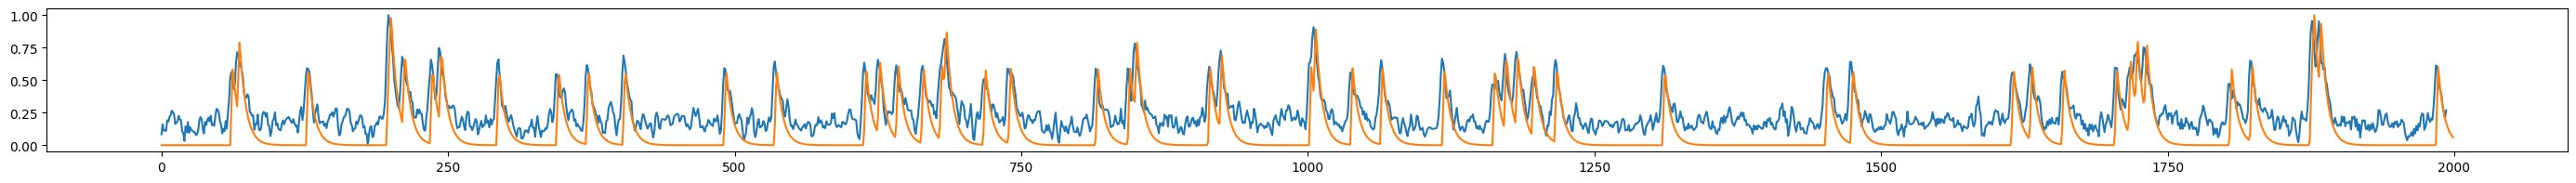

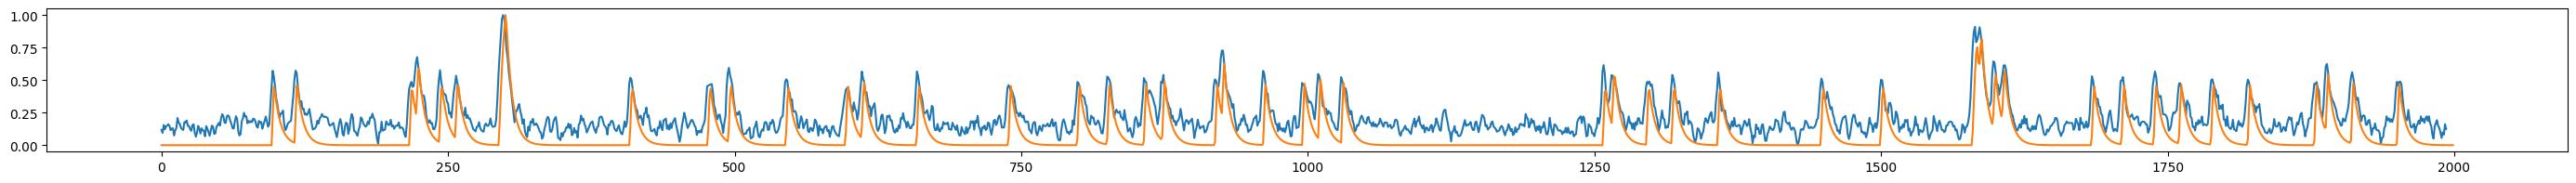

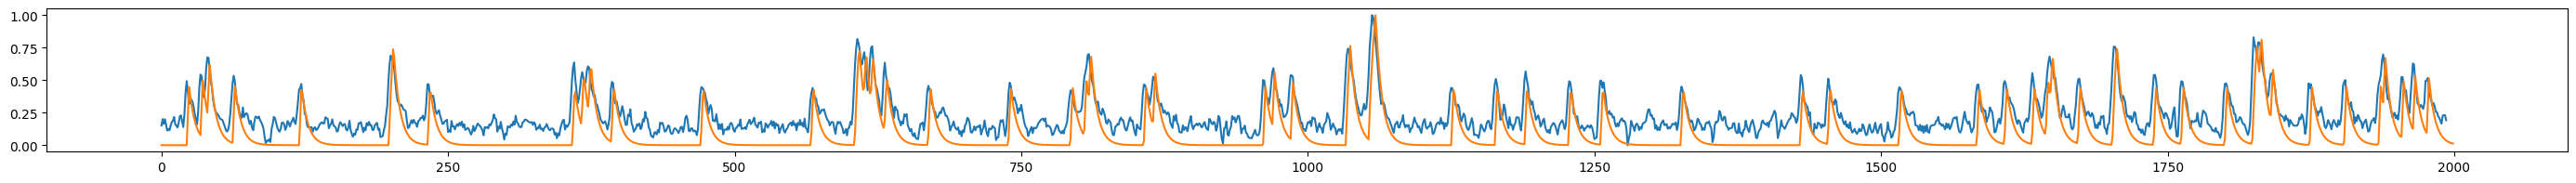

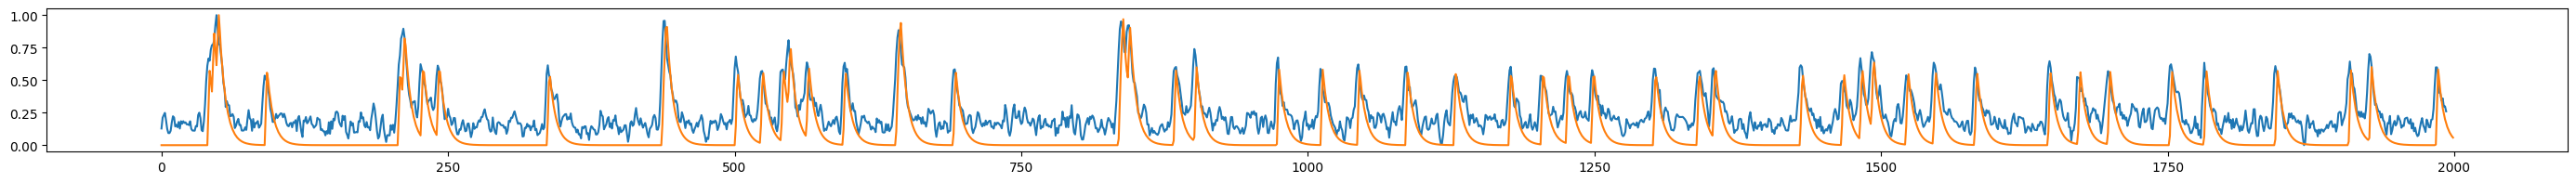

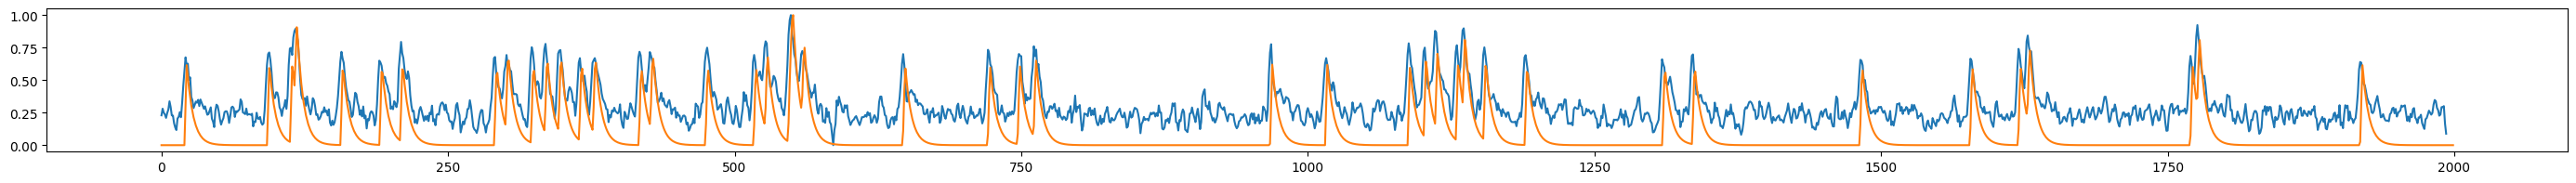

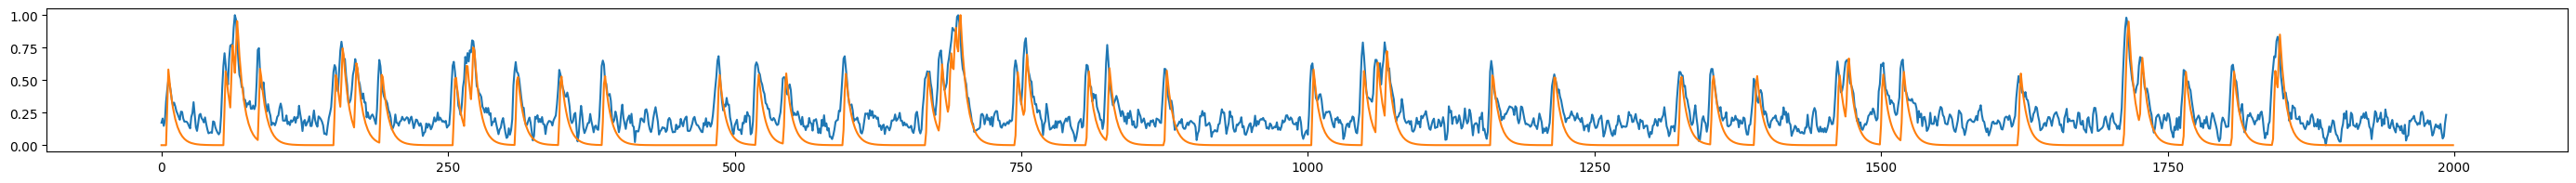

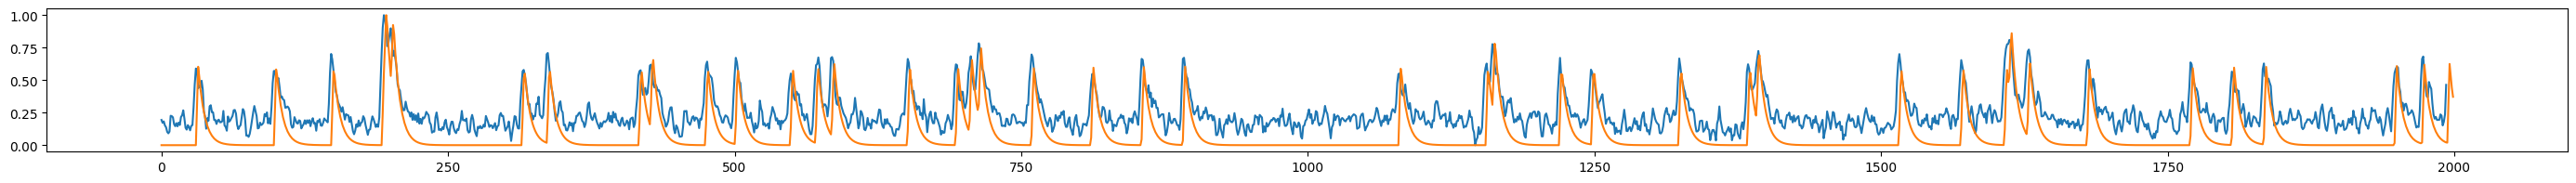

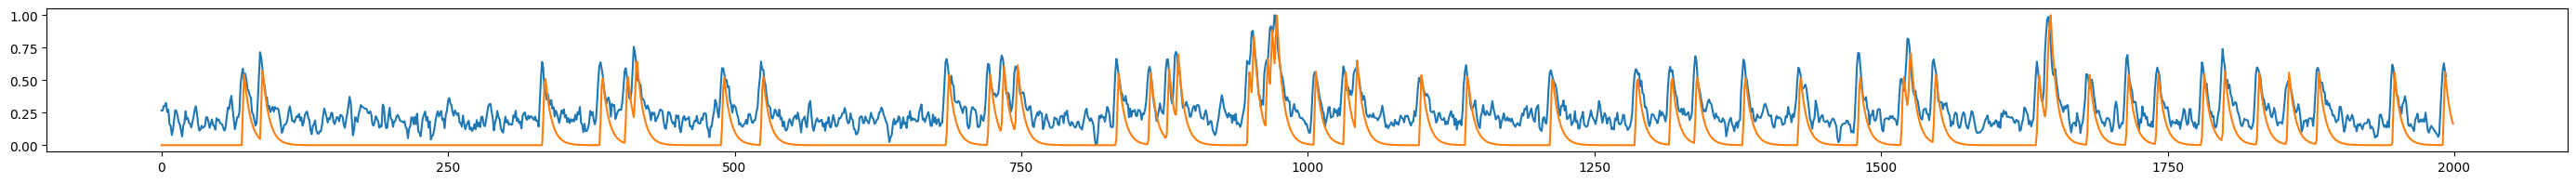

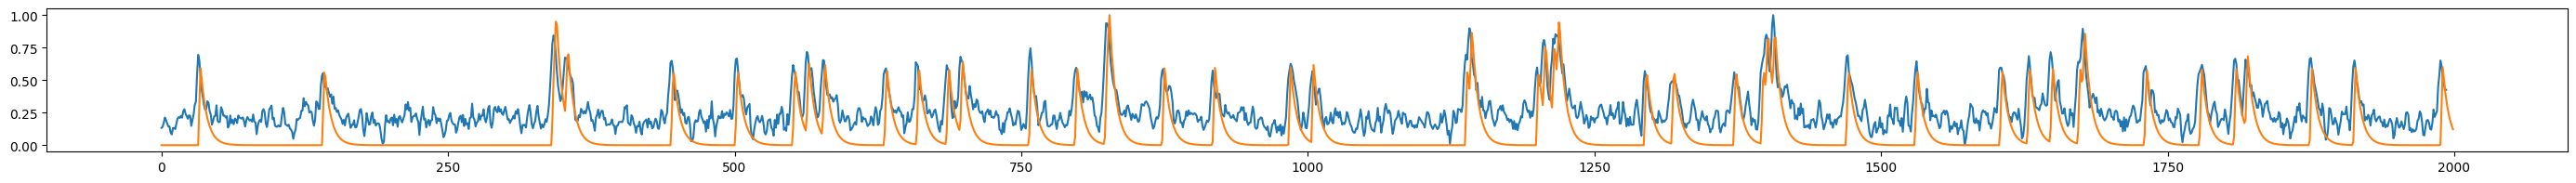

In [841]:
for i in range(n_components):
    filtered = -filts[component_ixs[i]] @ P
    
    filtered -= filtered.min()
    filtered /= filtered.max()
    
    fig = plt.figure(figsize=(35, 2))
    plt.plot(filtered)
    plt.plot(clean[i] / clean[i].max())
    plt.show()

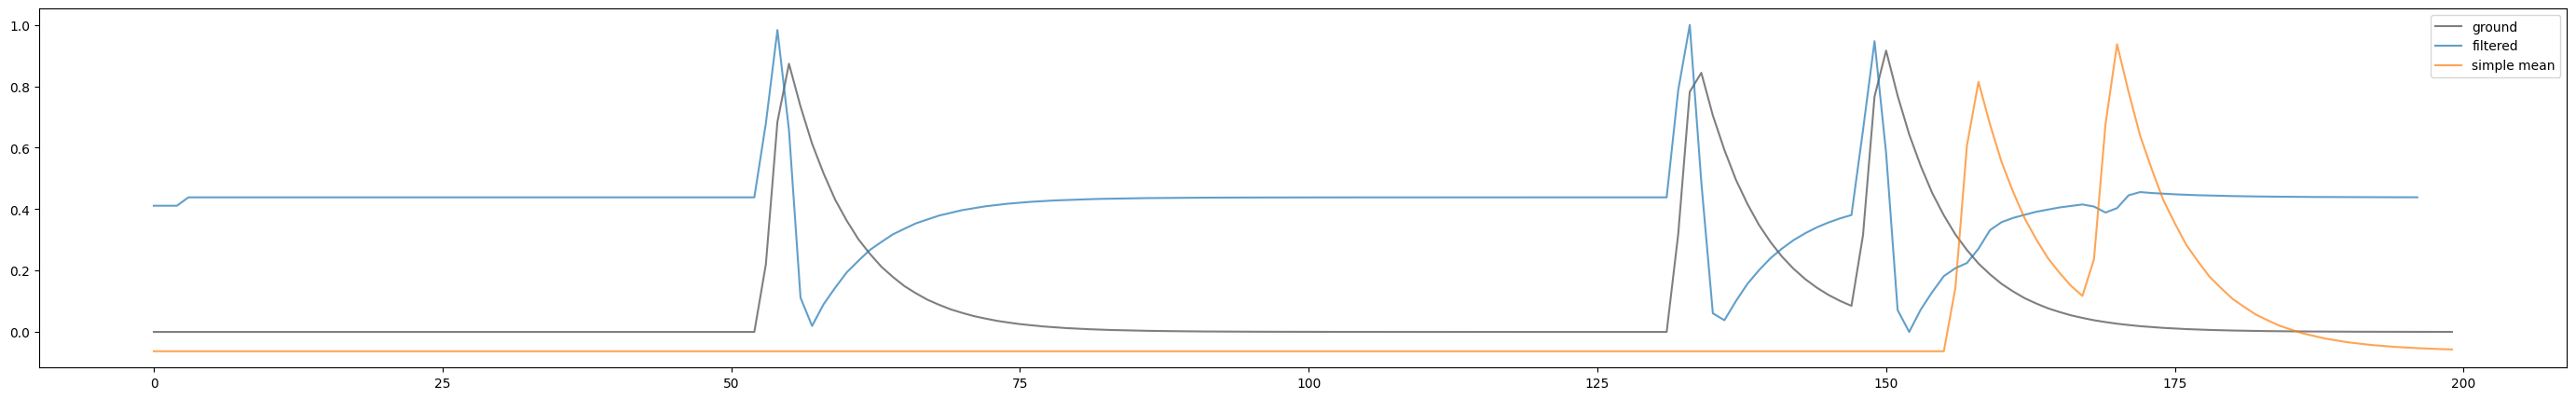

In [211]:
filtered = np.zeros(shape=(n_timepoints - int(w / 2)))
filtered[int(w / 2):] = filt2 @ P


filtered -= filtered.min()
filtered /= filtered.max()

indices = slice(0, 500)
fig = plt.figure(figsize=(35, 5))
plt.plot(clean[0, indices] / clean.max(), label="ground", alpha=0.5, c="k")
plt.plot(filtered[indices], label="filtered", alpha=0.7)
plt.plot(series[4:-1].mean(axis=0)[indices] / clean.max(), alpha=0.7, label="simple mean")
plt.legend()
plt.show()